In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler



In [3]:
PATH = r"bank.csv"   
df = pd.read_csv(PATH)
print("Shape:", df.shape)
df.head()

Shape: (8912, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   object 
 2   marital    8743 non-null   object 
 3   education  8885 non-null   object 
 4   default    8908 non-null   object 
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   object 
 7   loan       8882 non-null   object 
 8   contact    8881 non-null   object 
 9   day        8893 non-null   float64
 10  month      8884 non-null   object 
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   object 
 16  deposit    8903 non-null   object 
dtypes: float64(6), int64(1), object(10)
memory usage: 1.2+ MB


In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget distribution (incl. NaN):")
print(df["deposit"].value_counts(dropna=False))

Missing values per column:
age            0
job            7
marital      169
education     27
default        4
balance       13
housing       13
loan          30
contact       31
day           19
month         28
duration       7
campaign       8
pdays        145
previous       3
poutcome       0
deposit        9
dtype: int64

Duplicate rows: 0

Target distribution (incl. NaN):
deposit
no     4673
yes    4230
NaN       9
Name: count, dtype: int64


In [6]:
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
for col in cat_cols:
    print(f"{col}: {df[col].value_counts(dropna=False).to_dict()}\n")

job: {'management': 2078, 'blue-collar': 1554, 'technician': 1458, 'admin.': 1056, 'services': 744, 'retired': 606, 'self-employed': 314, 'unemployed': 294, 'student': 279, 'entrepreneur': 250, 'housemaid': 215, 'unknown': 57, nan: 7}

marital: {'married': 4980, 'single': 2751, 'divorced': 1012, nan: 169}

education: {'secondary': 4364, 'tertiary': 2940, 'primary': 1192, 'unknown': 389, nan: 27}

default: {'no': 8762, 'yes': 146, nan: 4}

housing: {'no': 4657, 'yes': 4242, nan: 13}

loan: {'no': 7703, 'yes': 1179, nan: 30}

contact: {'cellular': 6381, 'unknown': 1876, 'telephone': 624, nan: 31}

month: {'may': 2265, 'aug': 1208, 'jul': 1180, 'jun': 955, 'nov': 757, 'apr': 734, 'feb': 620, 'oct': 330, 'jan': 280, 'sep': 247, 'mar': 215, 'dec': 93, nan: 28}

poutcome: {'unknown': 6638, 'failure': 979, 'success': 880, 'other': 415}

deposit: {'no': 4673, 'yes': 4230, nan: 9}



In [7]:

before = len(df)
df = df.dropna(subset=["deposit"]).reset_index(drop=True)
print(f"Dropped {before - len(df)} rows with missing target")

text_cols = df.select_dtypes(exclude="number").columns.tolist()
for col in text_cols:
    df[col] = df[col].str.strip().str.lower()
    
print("Duplicates removed:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

Dropped 9 rows with missing target
Duplicates removed: 0


In [8]:

df[["job", "education"]] = df[["job", "education"]].replace("unknown", np.nan)


num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])


int_cols = ["age", "day", "duration", "campaign", "pdays", "previous"]
df[int_cols] = df[int_cols].round().astype(int)

print("Remaining missing values:", df.isnull().sum().sum())
df.info()

Remaining missing values: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8903 entries, 0 to 8902
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8903 non-null   int32  
 1   job        8903 non-null   object 
 2   marital    8903 non-null   object 
 3   education  8903 non-null   object 
 4   default    8903 non-null   object 
 5   balance    8903 non-null   float64
 6   housing    8903 non-null   object 
 7   loan       8903 non-null   object 
 8   contact    8903 non-null   object 
 9   day        8903 non-null   int32  
 10  month      8903 non-null   object 
 11  duration   8903 non-null   int32  
 12  campaign   8903 non-null   int32  
 13  pdays      8903 non-null   int32  
 14  previous   8903 non-null   int32  
 15  poutcome   8903 non-null   object 
 16  deposit    8903 non-null   object 
dtypes: float64(1), int32(6), object(10)
memory usage: 973.9+ KB


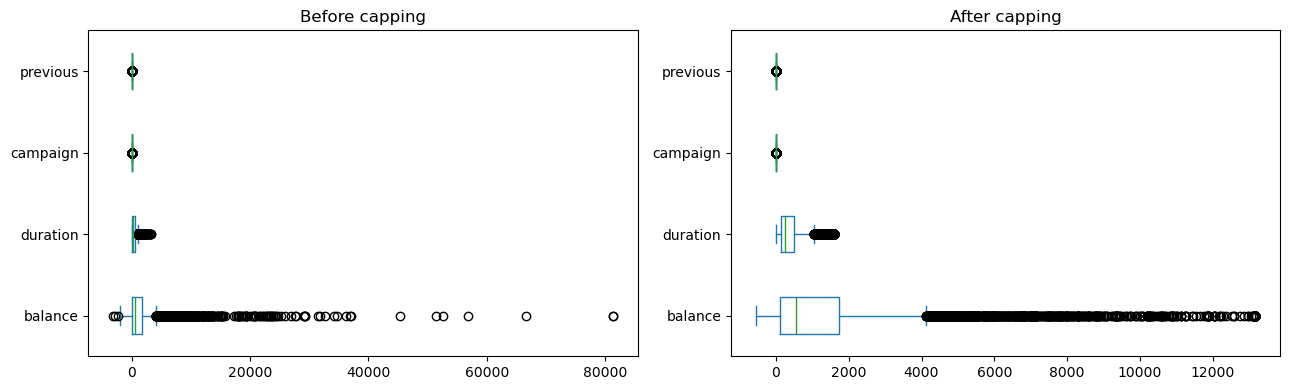

In [9]:
cap_cols = ["balance", "duration", "campaign", "previous"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df[cap_cols].plot(kind="box", ax=axes[0], vert=False); axes[0].set_title("Before capping")

for col in cap_cols:
    lo, hi = df[col].quantile([0.01, 0.99])
    df[col] = df[col].clip(lo, hi)

df[cap_cols].plot(kind="box", ax=axes[1], vert=False); axes[1].set_title("After capping")
plt.tight_layout(); plt.show()

In [10]:
# pdays == -1 means the client was never contacted in a previous campaign
df["previously_contacted"] = (df["pdays"] != -1).astype(int)
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit,previously_contacted
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5,may,1042.0,1,-1,0,unknown,yes,0
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5,may,1467.0,1,-1,0,unknown,yes,0
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5,may,1389.0,1,-1,0,unknown,yes,0
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5,may,673.0,2,-1,0,unknown,yes,0
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5,may,562.0,2,-1,0,unknown,yes,0


In [11]:

for col in ["default", "housing", "loan", "deposit"]:
    df[col] = df[col].map({"yes": 1, "no": 0})

df["education"] = df["education"].map({"primary": 0, "secondary": 1, "tertiary": 2})
months = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
df["month"] = df["month"].map({m: i for i, m in enumerate(months, start=1)})


nominal_cols = ["job", "marital", "contact", "poutcome"]
df_encoded = pd.get_dummies(df, columns=nominal_cols, drop_first=True, dtype=int)

print("Shape after encoding:", df_encoded.shape)
print("Any NaN left:", df_encoded.isnull().any().any())
df_encoded.head()

Shape after encoding: (8903, 31)
Any NaN left: False


,age,education,default,balance,housing,loan,day,month,duration,campaign,...,job_student,job_technician,job_unemployed,marital_married,marital_single,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown
0,59,1,0,2343.0,1,0,5,5,1042.0,1,...,0,0,0,1,0,0,1,0,0,1
1,56,1,0,45.0,0,0,5,5,1467.0,1,...,0,0,0,1,0,0,1,0,0,1
2,41,1,0,1270.0,1,0,5,5,1389.0,1,...,0,1,0,1,0,0,1,0,0,1
3,54,2,0,184.0,0,0,5,5,673.0,2,...,0,0,0,1,0,0,1,0,0,1
4,42,2,0,0.0,1,1,5,5,562.0,2,...,0,0,0,0,1,0,1,0,0,1


In [12]:
X = df_encoded.drop(columns="deposit")
y = df_encoded["deposit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scale_cols = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
scaler = StandardScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train target balance:", y_train.mean().round(3), "| Test:", y_test.mean().round(3))
X_train.head()

Train: (7122, 30) | Test: (1781, 30)
Train target balance: 0.475 | Test: 0.475


,age,education,default,balance,housing,loan,day,month,duration,campaign,...,job_student,job_technician,job_unemployed,marital_married,marital_single,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown
3586,-1.460729,1,0,-0.093088,0,0,0.637023,7,-0.171141,-0.646947,...,1,0,0,0,1,0,0,0,1,0
7975,-0.866371,1,0,0.412638,1,0,0.399160,11,-0.615699,-0.646947,...,0,1,0,1,0,0,0,0,0,1
5611,-0.696554,1,0,1.548176,0,0,1.350611,10,-0.630718,-0.646947,...,0,1,0,1,0,0,0,1,0,0
6023,0.831797,2,0,3.915622,1,0,-1.265879,5,-0.105058,-0.646947,...,0,0,0,1,0,0,1,0,0,1
6345,-0.526737,1,0,-0.192443,0,1,0.993817,7,-0.579654,-0.203827,...,0,1,0,0,1,0,0,0,0,1


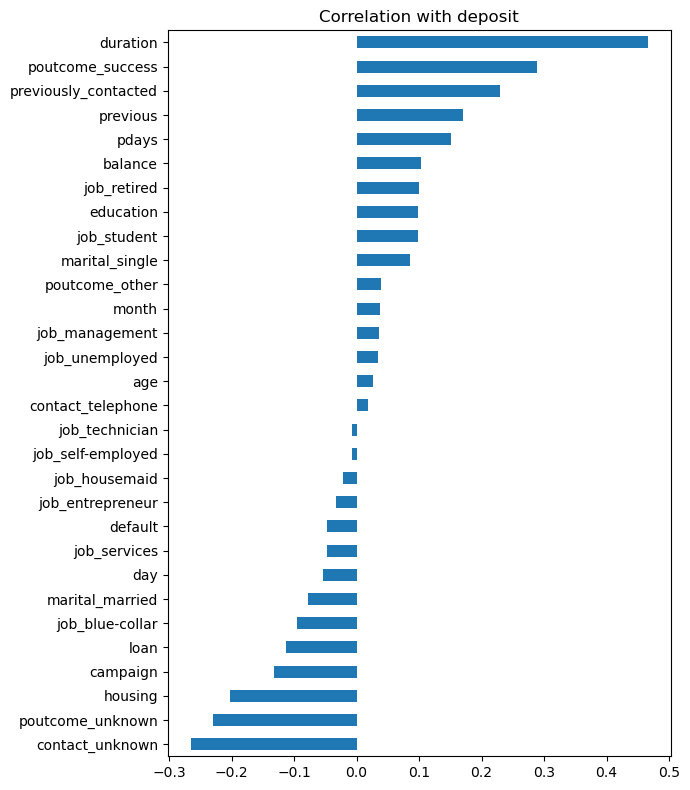

In [13]:
corr = df_encoded.corr()["deposit"].drop("deposit").sort_values()
corr.plot(kind="barh", figsize=(7, 8), title="Correlation with deposit")
plt.tight_layout(); plt.show()

In [14]:
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [15]:
svc = SVC(C=10,)

In [16]:
# svc.fit(X_train,y_train)

In [17]:
# y_pred = svc.predict(X_test)

In [18]:
# print(accuracy_score(y_test,y_pred))
# print(classification_report (y_test,y_pred))


In [19]:
# cm = confusion_matrix(y_test, y_pred)


# plt.figure(figsize=(6, 5))


# sns.heatmap(
#     cm,
#     annot=True,
#     fmt='d',
#     cmap='Blues',
#     cbar=False,
#     xticklabels=['Not Fraud', 'Fraud'],
#     yticklabels=['Not Fraud', 'Fraud'],
# )


# plt.xlabel('Predicted Label', fontsize=12)
# plt.ylabel('Actual Label', fontsize=12)
# plt.title('Confusion Matrix', fontsize=14)


# plt.show()

In [20]:
# svc_pram = {
#     'C' : [.1,1,10],
#     'kernel' : ['poly','rbf','linear'],
#     'gamma' :['auto', 'scale']
# }

In [21]:
# grid = GridSearchCV(svc,svc_pram, cv=5, scoring='accuracy')

In [22]:
# grid.fit(X_train,y_train)

In [23]:
# print(grid.best_params_)

In [24]:
# print(grid.best_estimator_)

In [25]:
# print(grid.best_score_)

In [26]:
from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor,plot_tree
from sklearn.model_selection import RandomizedSearchCV


In [27]:
rand_param = {
    'max_depth': [10,13,15],
    'min_samples_split':[3,4,5,6,7],
    'min_samples_leaf': [3,4,5]
}

In [28]:
radom_search = RandomizedSearchCV(estimator=DecisionTreeClassifier(),param_distributions=rand_param,cv =5,scoring='accuracy')

In [29]:
radom_search.fit(X_train,y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 13, ...], 'min_samples_leaf': [3, 4, ...], 'min_samples_split': [3, 4, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_c

In [30]:
y_pred = radom_search.predict(X_test)

In [31]:
print(radom_search.best_estimator_)

DecisionTreeClassifier(max_depth=10, min_samples_leaf=5, min_samples_split=4)


In [32]:
print(radom_search.best_score_)

0.8111468559038044


In [33]:
from sklearn.ensemble import ExtraTreesRegressor

rf = ExtraTreesRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Get top 10 important features
importances = pd.Series(rf.feature_importances_, index=X.columns)

importances = importances.sort_values(ascending=False)

selected_columns = importances.sort_values(ascending=False).index[:5]
print("Random Forest Selected Features:", selected_columns.tolist())
selected_features = importances.nlargest(5)
print("Random Forest Selected Features:", selected_features.tolist())

Random Forest Selected Features: ['duration', 'month', 'poutcome_success', 'day', 'age']
Random Forest Selected Features: [0.3259175669835144, 0.09792571530597632, 0.09147860146282313, 0.06059593890570422, 0.05200890661149058]


Extra Trees Selected Features: ['duration', 'month', 'poutcome_success', 'day', 'age']


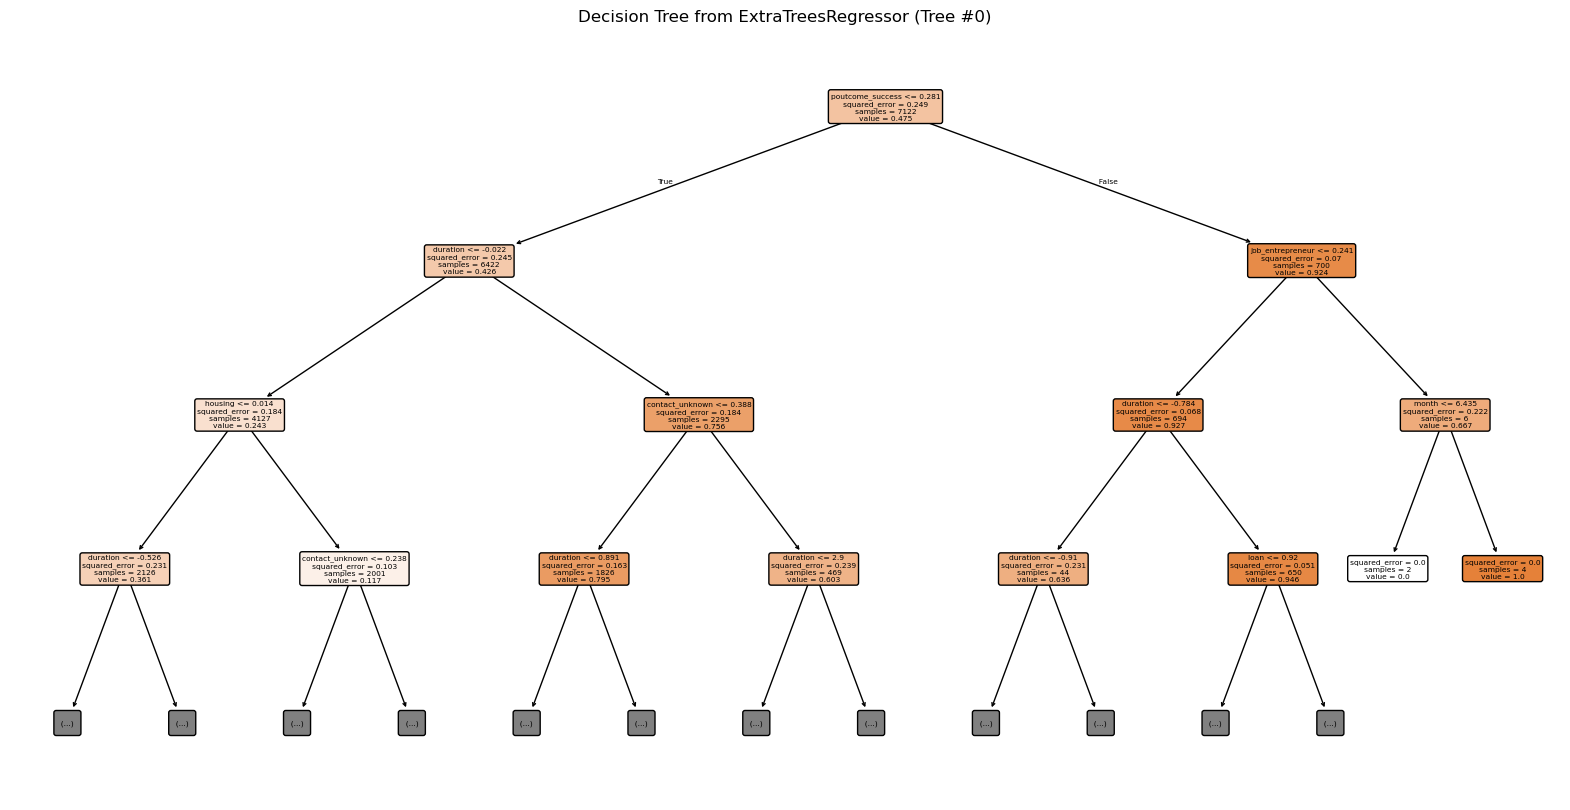

In [34]:


rf = ExtraTreesRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Get feature importances
importances = pd.Series(rf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

selected_columns = importances.index[:5]
print("Extra Trees Selected Features:", selected_columns.tolist())

# --- Plot the first tree in the ensemble ---
plt.figure(figsize=(20, 10))
plot_tree(
    rf.estimators_[0], 
    feature_names=X.columns, 
    filled=True, 
    rounded=True, 
    max_depth=3  # Optional: limit depth if the tree is too large to view clearly
)
plt.title("Decision Tree from ExtraTreesRegressor (Tree #0)")
plt.show()

In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [ ]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [37]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

In [38]:
from tqdm import tqdm

  0%|          | 0/15 [00:00<?, ?it/s]

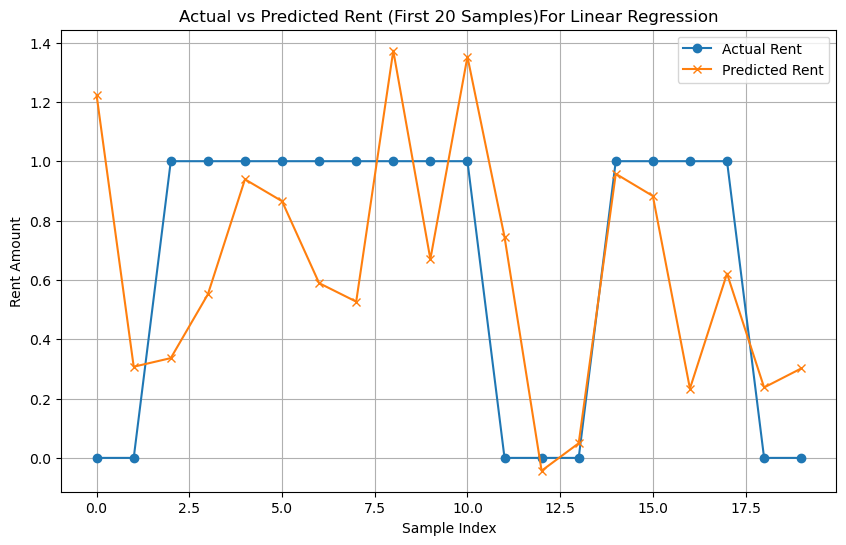

  7%|▋         | 1/15 [00:00<00:07,  1.96it/s]

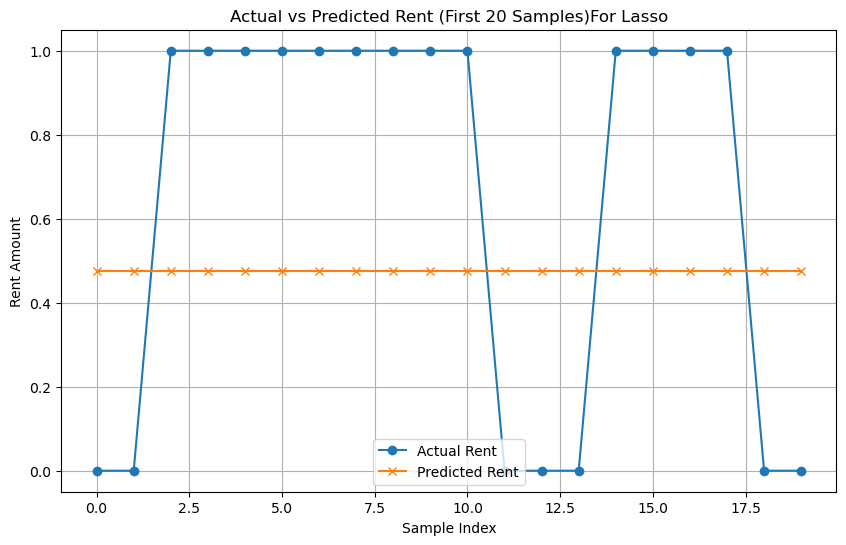

 13%|█▎        | 2/15 [00:00<00:05,  2.17it/s]

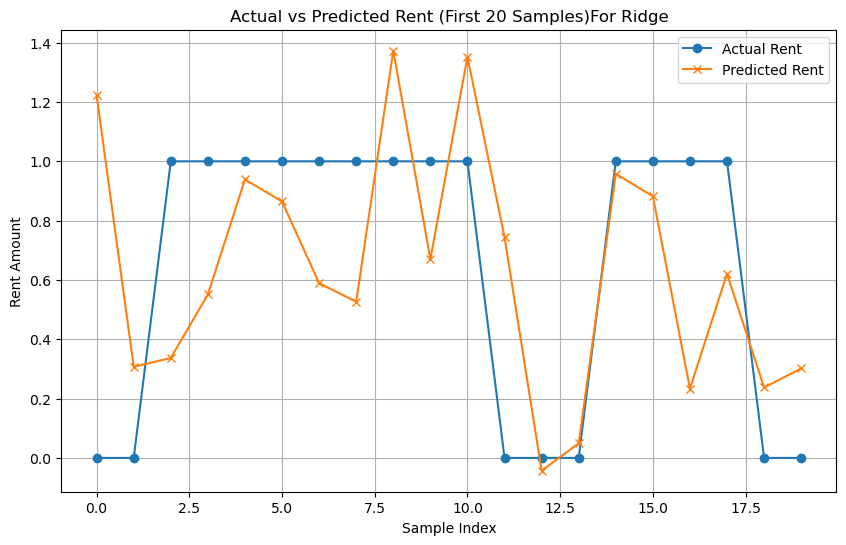

 20%|██        | 3/15 [00:01<00:05,  2.36it/s]e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "e:\anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, ar

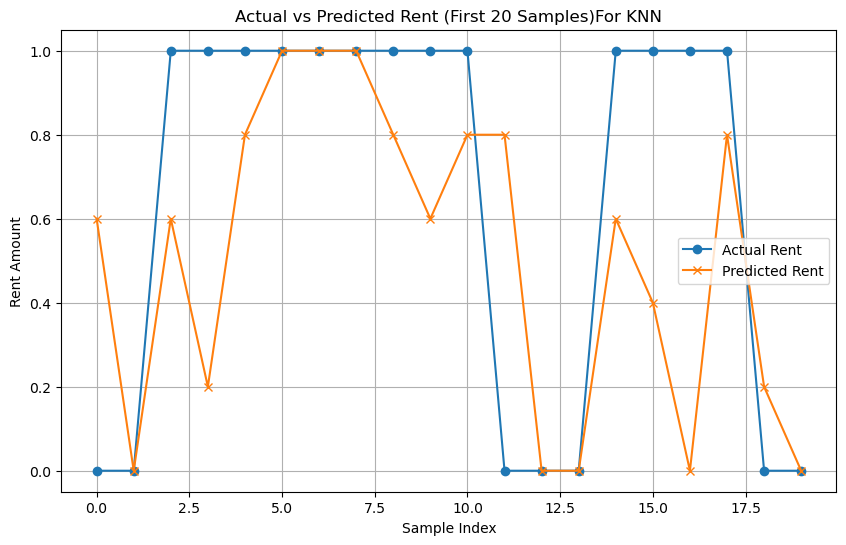

 27%|██▋       | 4/15 [00:02<00:09,  1.11it/s]

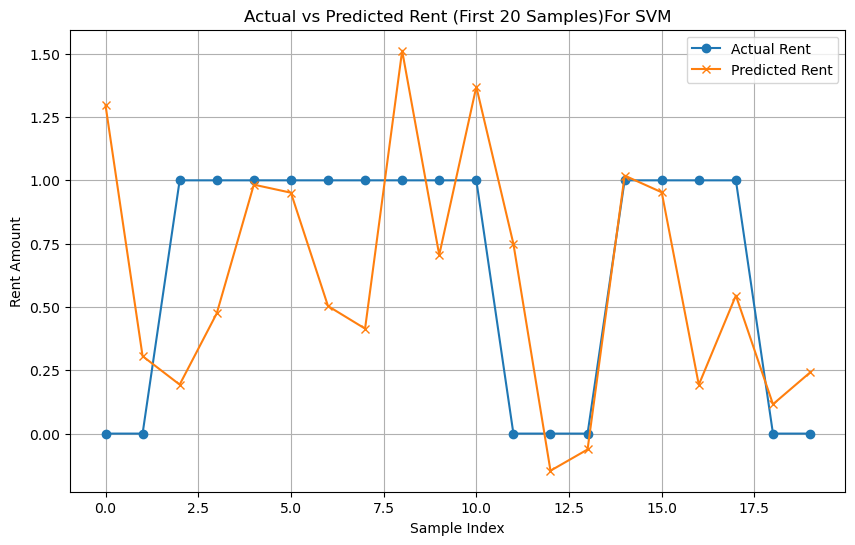

 33%|███▎      | 5/15 [14:51<53:30, 321.04s/it]

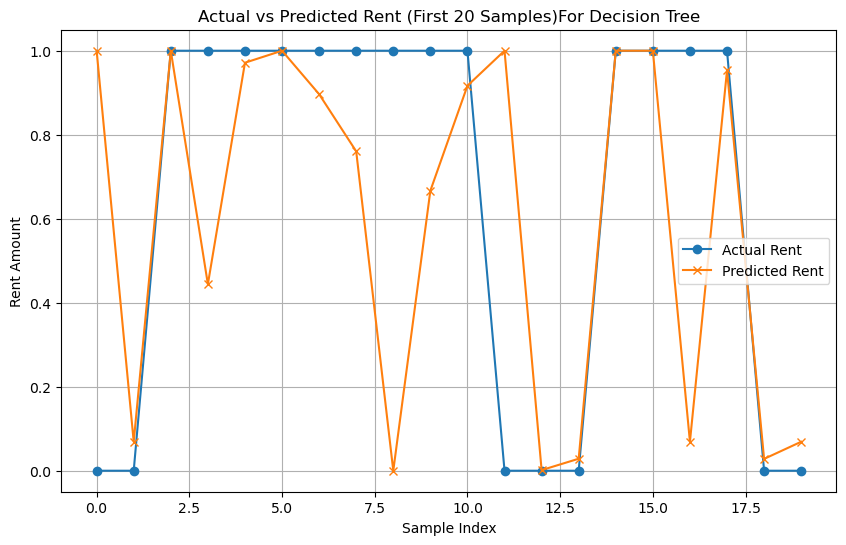

 40%|████      | 6/15 [14:51<31:48, 212.00s/it]

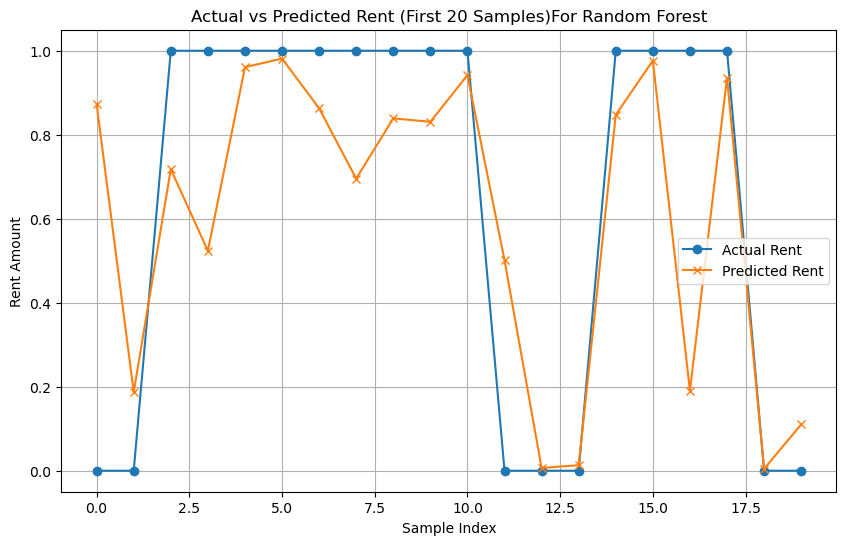

 47%|████▋     | 7/15 [14:53<19:05, 143.24s/it]

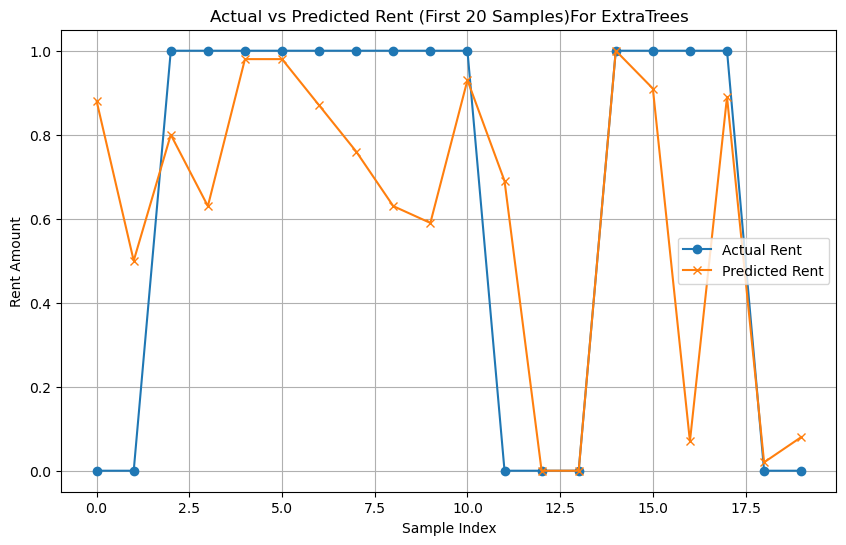

 53%|█████▎    | 8/15 [14:57<11:32, 98.95s/it] 

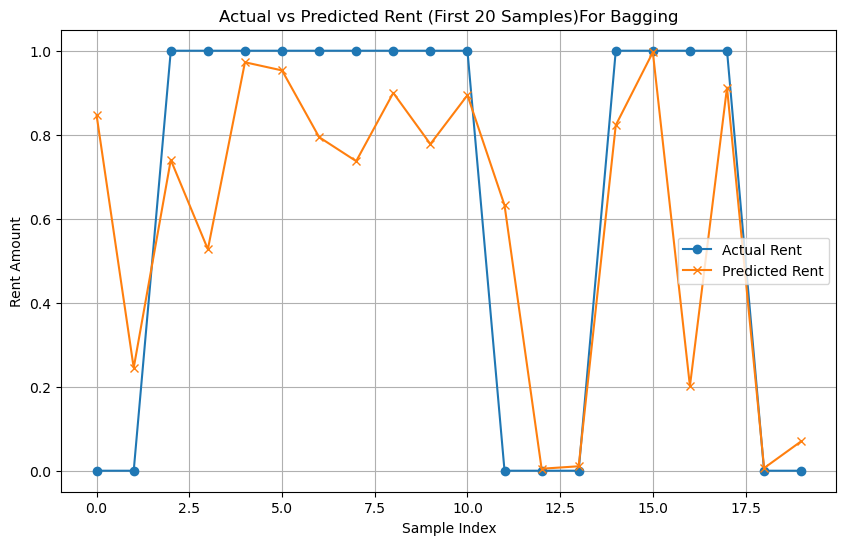

 60%|██████    | 9/15 [15:00<06:52, 68.76s/it]

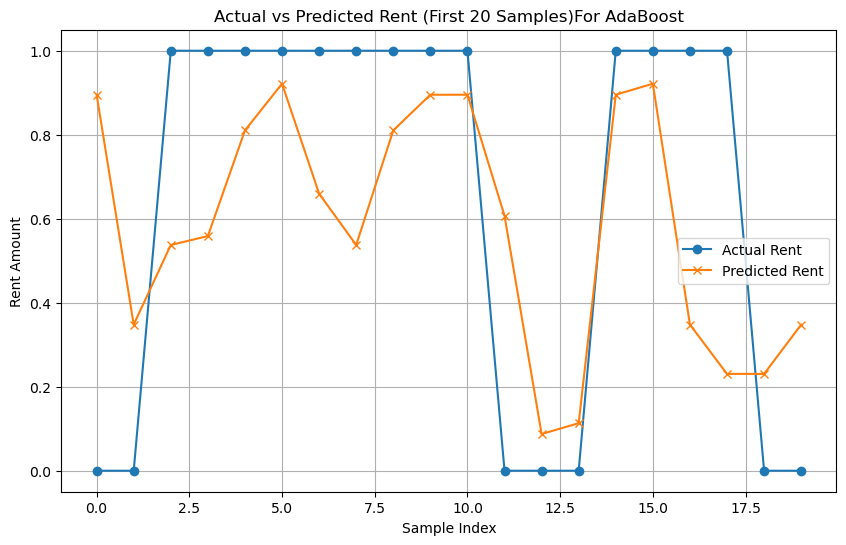

 67%|██████▋   | 10/15 [15:00<03:58, 47.72s/it]

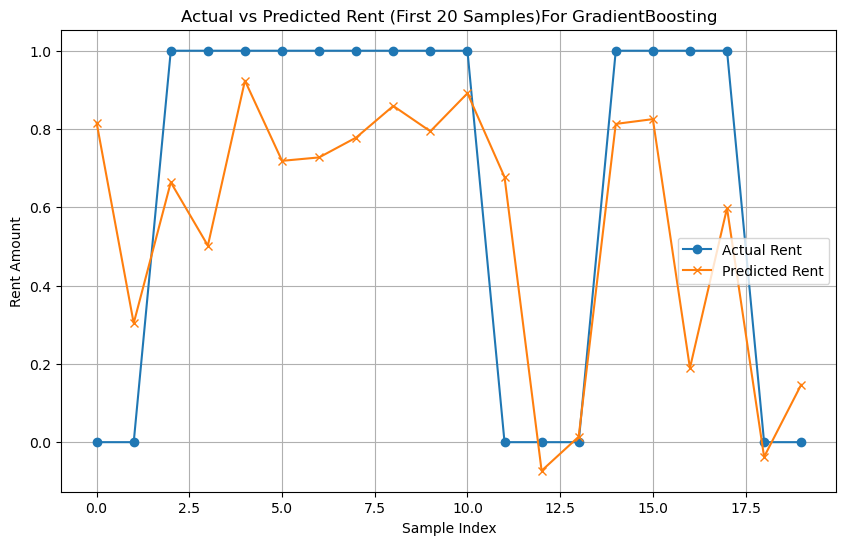

 73%|███████▎  | 11/15 [15:02<02:14, 33.62s/it]

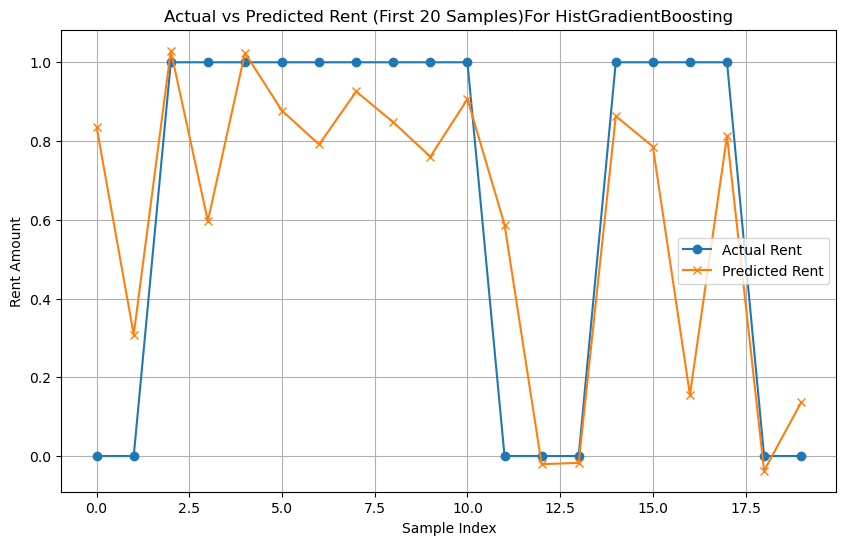

 80%|████████  | 12/15 [16:04<02:06, 42.20s/it]

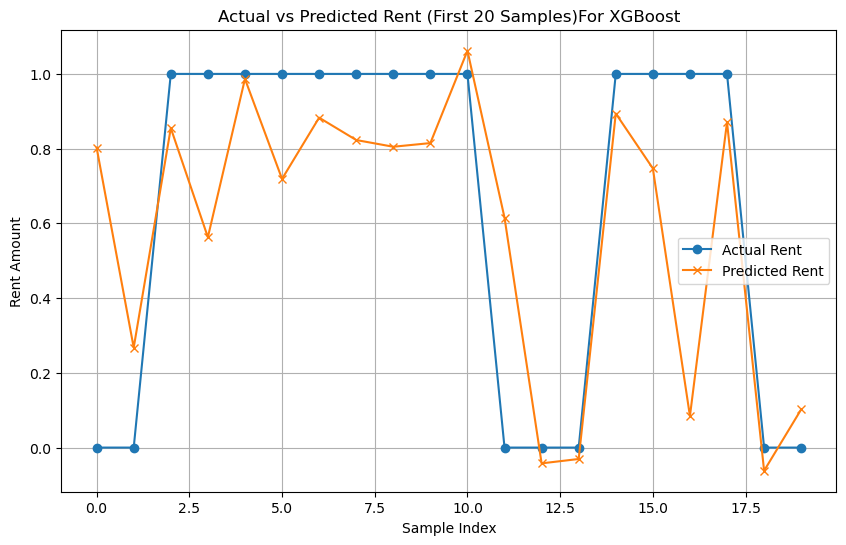

 87%|████████▋ | 13/15 [16:13<01:04, 32.23s/it]

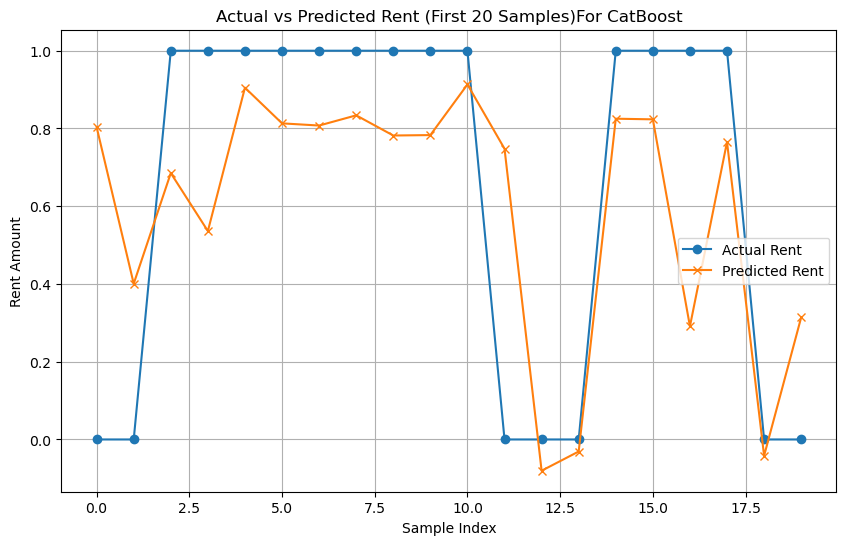

 93%|█████████▎| 14/15 [16:14<00:22, 22.87s/it]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.036133 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 954
[LightGBM] [Info] Number of data points in the train set: 7122, number of used features: 30
[LightGBM] [Info] Start training from score 0.475147


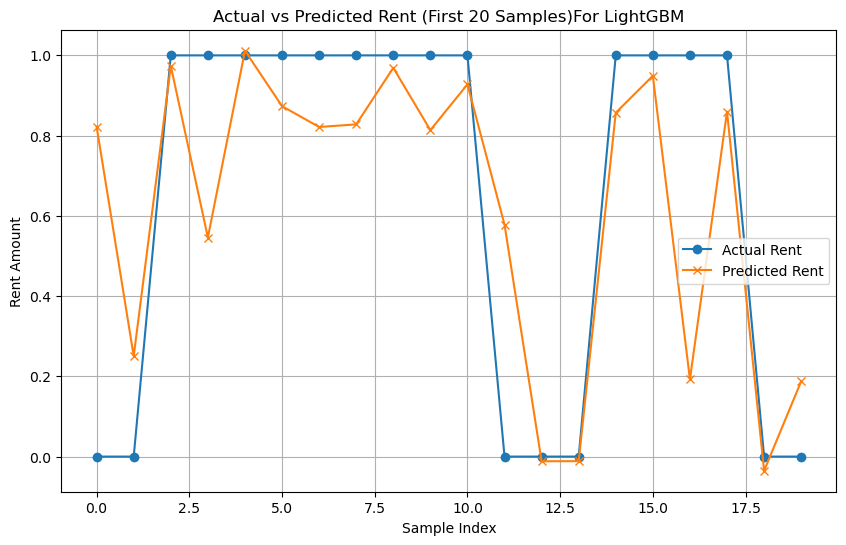

100%|██████████| 15/15 [16:42<00:00, 66.83s/it]


In [39]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [40]:
error = pd.DataFrame(errors)

In [41]:
error

,Linear Regression,Lasso,Ridge,KNN,SVM,Decision Tree,Random Forest,ExtraTrees,Bagging,AdaBoost,GradientBoosting,HistGradientBoosting,XGBoost,CatBoost,LightGBM
MAE Train,0.324886,4.987647e-01,0.324916,0.194243,0.311097,0.149697,0.169523,0.000000,0.168120,0.323732,0.238628,0.168650,0.165627,0.225862,0.168906
MAE Test,0.331340,4.987581e-01,0.331362,0.257383,0.317321,0.234495,0.233882,0.234767,0.232341,0.331974,0.259182,0.217500,0.229505,0.248692,0.216862
MSE Train,0.149009,2.493823e-01,0.149016,0.091396,0.159819,0.074849,0.063361,0.000000,0.062576,0.146842,0.103330,0.066273,0.060915,0.095401,0.066892
MSE Test,0.154882,2.493757e-01,0.154875,0.148411,0.166094,0.156828,0.116100,0.123618,0.115062,0.154064,0.120683,0.108355,0.112504,0.114825,0.107456
RMSE Train,0.386017,4.993820e-01,0.386026,0.302317,0.399773,0.273585,0.251717,0.000000,0.250153,0.383200,0.321450,0.257436,0.246810,0.308871,0.258634
RMSE Test,0.393550,4.993753e-01,0.393541,0.385241,0.407546,0.396015,0.340734,0.351594,0.339207,0.392510,0.347394,0.329174,0.335416,0.338859,0.327804
R2 Train,0.402486,0.000000e+00,0.402458,0.633512,0.359141,0.699864,0.745927,1.000000,0.749075,0.411177,0.585656,0.734250,0.755735,0.617451,0.731770
R2 Test,0.378923,-7.135342e-08,0.378951,0.404870,0.333962,0.371119,0.534439,0.504290,0.538601,0.382202,0.516061,0.565493,0.548858,0.539550,0.569102
